# Aspect-based Sentiment Analysis on Hotel Reviews
**UE24CS352A - Machine Learning Mini-Project**

**Goal:** from the text of a TripAdvisor hotel review, predict the star rating (1-5) for the *overall* experience and for each *aspect* (cleanliness, value, location, rooms, sleep quality), then convert stars to polarity (negative / neutral / positive).

**Pipeline:** load data -> explore -> train/test split -> bag-of-words (1-3 grams) -> one model per aspect (Linear SVM, Naive Bayes, Ridge) -> evaluate -> compare aspect-trained vs overall-trained -> save models -> live demo.

Reference: *Aspect-based Sentiment Analysis on Hotel Reviews*, CS229 Stanford (2016).

## Step 0: Setup
The next cell installs the needed packages **into the environment this notebook is running in** (safe to re-run; it does nothing if they are already installed).

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import Ridge
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

warnings.filterwarnings("ignore")
SEED = 42
os.makedirs("outputs", exist_ok=True)

## Step 1: Configuration
- Download **data.csv** from https://huggingface.co/datasets/jniimi/tripadvisor-review-rating (Files and versions tab) and put it in the **same folder as this notebook**.
- `DATA_FILE` can be a `.csv`, `.parquet` or `.pkl` path. (`"hf"` auto-downloads the pickle but needs `pip install huggingface_hub`.)
- `MAX_REVIEWS`: use a subset so it runs on a laptop. Increase it if your machine copes.

In [2]:
DATA_FILE   = os.environ.get("ABSA_DATA", "data.csv")
MAX_REVIEWS = int(os.environ.get("ABSA_MAX", 30000))
ALL_ASPECTS = ["overall", "value", "rooms", "location", "cleanliness", "sleep_quality"]

## Step 2: Load the data
Each row is one review: text + star ratings. Ratings outside 1-5 (e.g. -1, 0) mean *not rated* and are turned into `NaN` so we never train on a rating that does not exist. Very short reviews are dropped.

In [3]:
def load_data(path, max_reviews):
    if path == "hf":
        from huggingface_hub import hf_hub_download
        path = hf_hub_download("jniimi/tripadvisor-review-rating", repo_type="dataset", filename="data.pkl")
    if not os.path.exists(path):
        raise FileNotFoundError(f"'{path}' not found. Download data.csv and place it next to this notebook "
                                f"(current folder: {os.getcwd()}), or fix DATA_FILE above.")
    keep = set(ALL_ASPECTS) | {"review", "text", "rating"}      # read only the columns we need (saves RAM)
    if path.endswith(".pkl"):       df = pd.read_pickle(path)
    elif path.endswith(".parquet"): df = pd.read_parquet(path)
    else:                           df = pd.read_csv(path, usecols=lambda c: c in keep)

    if "overall" not in df and "rating" in df:
        df = df.rename(columns={"rating": "overall"})
    df["text"] = df["review"] if "review" in df else df["text"]

    if len(df) > max_reviews * 2:                       # sample early to save RAM
        df = df.sample(max_reviews * 2, random_state=SEED)
    for a in ALL_ASPECTS:
        if a not in df: df[a] = np.nan
        df[a] = pd.to_numeric(df[a], errors="coerce")
        df.loc[(df[a] < 1) | (df[a] > 5), a] = np.nan
    df["text"] = df["text"].fillna("").astype(str)
    df = df[df["text"].str.len() > 20].dropna(subset=["overall"]).reset_index(drop=True)
    if len(df) > max_reviews:
        df = df.sample(max_reviews, random_state=SEED).reset_index(drop=True)
    return df

df = load_data(DATA_FILE, MAX_REVIEWS)
ASPECTS = [a for a in ALL_ASPECTS if df[a].notna().sum() >= 500]
print(f"{len(df):,} reviews | aspects used: {ASPECTS}")
df[["text"] + ASPECTS].head()

30,000 reviews | aspects used: ['overall', 'value', 'rooms', 'location', 'cleanliness', 'sleep_quality']


,text,overall,value,rooms,location,cleanliness,sleep_quality
0,Lively location\nI have just returned from a 5...,4.0,4.0,4.0,4.0,5.0,5.0
1,"Great Location, Staff, Rate & Rooms - Skip the...",4.0,5.0,4.0,5.0,5.0,5.0
2,"Ok, but dated\nOverall this was an ok Sheraton...",3.0,4.0,3.0,5.0,4.0,3.0
3,"Chicago Experience\nI love the room, the bed, ...",5.0,4.0,5.0,5.0,4.0,4.0
4,OK Hotel Near Lax\nMy wife and I spent one nig...,3.0,3.0,3.0,4.0,3.0,4.0


## Step 3: Explore the data
How many reviews rate each aspect, and how are the stars distributed? Real review data is **imbalanced**: most ratings are 4-5 stars, which is why accuracy alone can mislead.

Share of reviews that rate each aspect (%):
overall          100.0
value            100.0
rooms            100.0
location         100.0
cleanliness      100.0
sleep_quality    100.0
dtype: float64


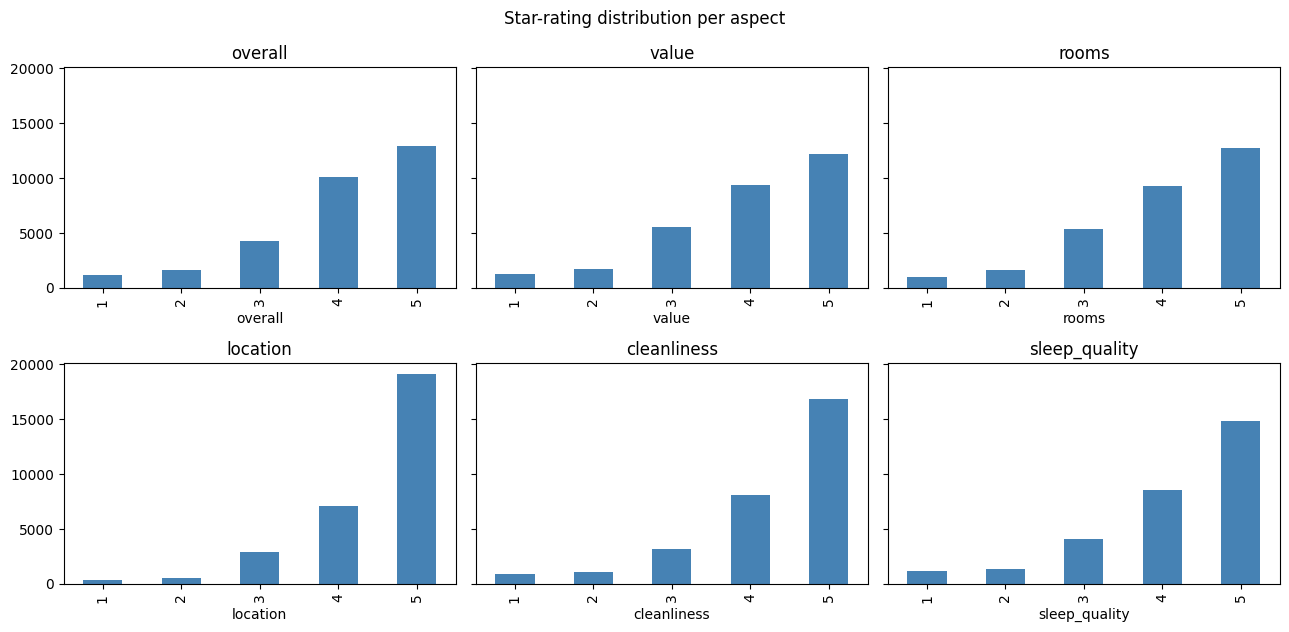

In [4]:
print("Share of reviews that rate each aspect (%):")
print((df[ASPECTS].notna().mean() * 100).round(1))

n = len(ASPECTS); cols = 3; rows = int(np.ceil(n / cols))
fig, axes = plt.subplots(rows, cols, figsize=(13, 3.2 * rows), sharey=True, squeeze=False)
for ax in axes.ravel()[n:]: ax.axis("off")
for ax, a in zip(axes.ravel(), ASPECTS):
    df[a].dropna().astype(int).value_counts().sort_index().plot.bar(ax=ax, color="steelblue")
    ax.set_title(a)
plt.suptitle("Star-rating distribution per aspect"); plt.tight_layout()
plt.savefig("outputs/rating_distribution.png", dpi=130); plt.show()

## Step 4: Polarity and train/test split
- **Polarity:** more than 3 stars = positive, exactly 3 = neutral, fewer than 3 = negative. It is an easier version of the star task.
- **Split:** we train on 2/3 of the reviews and test on the hidden 1/3. Testing on reviews the model has seen would only measure memorisation.

In [5]:
POL_NAME = {0: "negative", 1: "neutral", 2: "positive"}
def polarity(r):
    r = np.asarray(r)
    return np.where(r > 3, 2, np.where(r < 3, 0, 1))

train_df, test_df = train_test_split(df, test_size=1/3, random_state=SEED)
print(len(train_df), "train reviews |", len(test_df), "test reviews")

20000 train reviews | 10000 test reviews


## Step 5: Turn text into numbers (bag of words, 1-3 grams)
Models need numbers, so each review becomes a vector of word/phrase counts.
- **n-grams (1-3):** phrases like *"not good"* keep context that single words lose.
- **No TF-IDF:** the Stanford report found that down-weighting common words hurts here, because sentiment words ("great", "dirty") are common.
- **min_df=2, max_df=20%:** drop typos/one-offs and overly generic phrases.

In [6]:
vec = CountVectorizer(lowercase=True, ngram_range=(1, 3), min_df=2, max_df=0.20,
                      max_features=300_000, dtype=np.float32)
X_train_all = vec.fit_transform(train_df["text"])   # learn vocabulary from TRAIN only
X_test_all  = vec.transform(test_df["text"])
print("Feature matrix:", X_train_all.shape, "| vocabulary:", f"{len(vec.vocabulary_):,}")

Feature matrix: (20000, 300000) | vocabulary: 300,000


## Step 6: Models and metrics
Three models are trained **per aspect**:
- **Linear SVM** (`class_weight="balanced"` so rare classes such as 1-star count more), a strong standard text classifier.
- **Multinomial Naive Bayes**, a fast baseline.
- **Ridge regression**, which predicts a number and is rounded to the nearest star.

Metrics: **star accuracy** (exact match), **within-1 accuracy** (off by at most one star), **macro-F1** (averages all classes equally, so rare ones matter), and **polarity accuracy**.

In [7]:
def make_models():
    return {"LinearSVM": LinearSVC(C=0.1, class_weight="balanced", random_state=SEED),
            "NaiveBayes": MultinomialNB(alpha=0.5),
            "Ridge": Ridge(alpha=5.0, solver="sparse_cg")}

def predict_stars(name, model, X):
    p = model.predict(X)
    return np.clip(np.rint(p), 1, 5).astype(int) if name == "Ridge" else p

def evaluate(y, p):
    return {"star_acc": accuracy_score(y, p),
            "within1_acc": float(np.mean(np.abs(y - p) <= 1)),
            "macro_f1": f1_score(y, p, average="macro"),
            "polarity_acc": accuracy_score(polarity(y), polarity(p))}

## Step 7: Train one model per aspect and evaluate
Each aspect uses only the reviews that actually have a rating for it.

In [8]:
results, svm_models = [], {}
for aspect in ASPECTS:
    tr = train_df[aspect].notna().values;  te = test_df[aspect].notna().values
    Xtr, ytr = X_train_all[tr], train_df.loc[tr, aspect].astype(int).values
    Xte, yte = X_test_all[te],  test_df.loc[te, aspect].astype(int).values
    for name, model in make_models().items():
        model.fit(Xtr, ytr)
        results.append({"aspect": aspect, "model": name, "n_train": len(ytr),
                        **evaluate(yte, predict_stars(name, model, Xte))})
        if name == "LinearSVM": svm_models[aspect] = model

res = pd.DataFrame(results)
res.to_csv("outputs/results_all_models.csv", index=False)
res.round(3)

,aspect,model,n_train,star_acc,within1_acc,macro_f1,polarity_acc
0,overall,LinearSVM,20000,0.618,0.956,0.531,0.839
1,overall,NaiveBayes,20000,0.651,0.972,0.547,0.854
2,overall,Ridge,20000,0.560,0.957,0.451,0.824
3,value,LinearSVM,20000,0.485,0.892,0.416,0.756
4,value,NaiveBayes,20000,0.525,0.914,0.437,0.775
5,value,Ridge,20000,0.445,0.916,0.375,0.757
6,rooms,LinearSVM,20000,0.536,0.921,0.463,0.779
7,rooms,NaiveBayes,20000,0.560,0.938,0.455,0.787
8,rooms,Ridge,20000,0.499,0.937,0.416,0.779
9,location,LinearSVM,20000,0.626,0.921,0.312,0.861


### Majority-class baseline (sanity check)
Ratings are heavily skewed toward 5 stars, so a "model" that always predicts the most common star can already look decent. This table shows what that trivial baseline scores, so we can see how much our models genuinely **learn** beyond guessing.

In [9]:
base = []
for aspect in ASPECTS:
    tr = train_df[aspect].notna().values; te = test_df[aspect].notna().values
    maj = int(train_df.loc[tr, aspect].mode()[0])
    y = test_df.loc[te, aspect].astype(int).values
    base.append({"aspect": aspect, "model": "Baseline(majority)", "majority_star": maj,
                 **evaluate(y, np.full_like(y, maj))})
baseline_df = pd.DataFrame(base).set_index("aspect")
baseline_df.to_csv("outputs/baseline_majority.csv")

cmp_models = pd.concat([res[["aspect", "model", "star_acc", "polarity_acc"]],
                        baseline_df.reset_index()[["aspect", "model", "star_acc", "polarity_acc"]]])
print("STAR accuracy: models vs baseline")
display(cmp_models.pivot(index="aspect", columns="model", values="star_acc").loc[ASPECTS].round(3))
print("POLARITY accuracy: models vs baseline")
display(cmp_models.pivot(index="aspect", columns="model", values="polarity_acc").loc[ASPECTS].round(3))

STAR accuracy: models vs baseline


model,Baseline(majority),LinearSVM,NaiveBayes,Ridge
aspect,,,,
overall,0.432,0.618,0.651,0.560
value,0.409,0.485,0.525,0.445
rooms,0.425,0.536,0.560,0.499
location,0.638,0.626,0.646,0.557
cleanliness,0.560,0.589,0.626,0.548
sleep_quality,0.496,0.547,0.578,0.496


POLARITY accuracy: models vs baseline


model,Baseline(majority),LinearSVM,NaiveBayes,Ridge
aspect,,,,
overall,0.764,0.839,0.854,0.824
value,0.724,0.756,0.775,0.757
rooms,0.732,0.779,0.787,0.779
location,0.876,0.861,0.862,0.861
cleanliness,0.826,0.845,0.850,0.839
sleep_quality,0.776,0.799,0.801,0.792


### Results summary (best model: Linear SVM)

,n_train,star_acc,within1_acc,macro_f1,polarity_acc
aspect,,,,,
overall,20000,0.618,0.956,0.531,0.839
value,20000,0.485,0.892,0.416,0.756
rooms,20000,0.536,0.921,0.463,0.779
location,20000,0.626,0.921,0.312,0.861
cleanliness,20000,0.589,0.930,0.424,0.845
sleep_quality,20000,0.547,0.902,0.413,0.799


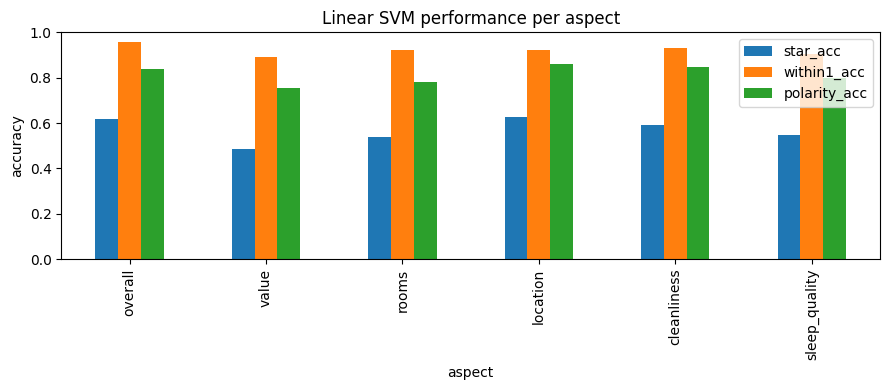

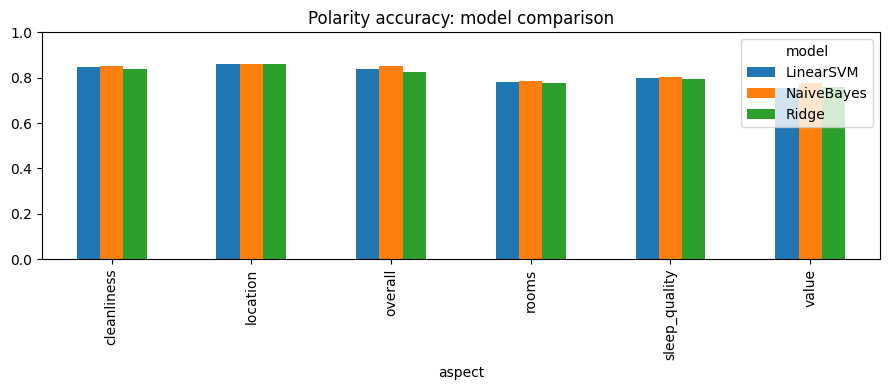

In [10]:
svm = res[res.model == "LinearSVM"].set_index("aspect")
display(svm[["n_train", "star_acc", "within1_acc", "macro_f1", "polarity_acc"]].round(3))

svm[["star_acc", "within1_acc", "polarity_acc"]].plot.bar(figsize=(9, 4))
plt.title("Linear SVM performance per aspect"); plt.ylim(0, 1); plt.ylabel("accuracy")
plt.tight_layout(); plt.savefig("outputs/svm_per_aspect.png", dpi=130); plt.show()

res.pivot(index="aspect", columns="model", values="polarity_acc").plot.bar(figsize=(9, 4))
plt.title("Polarity accuracy: model comparison"); plt.ylim(0, 1)
plt.tight_layout(); plt.savefig("outputs/model_comparison_polarity.png", dpi=130); plt.show()

### Confusion matrix (overall rating, Linear SVM)
Rows = true stars, columns = predicted. Most errors should sit next to the diagonal (4 vs 5, 2 vs 3).

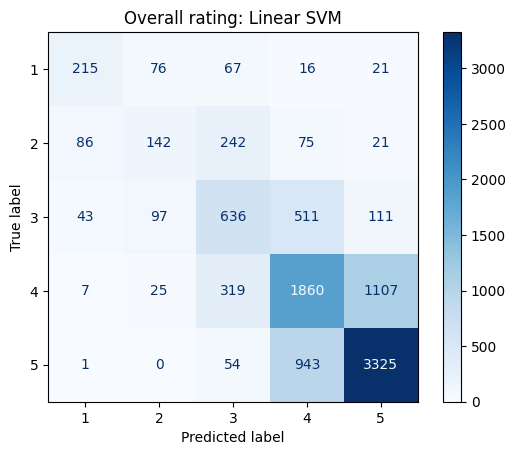

In [11]:
te = test_df["overall"].notna().values
yte = test_df.loc[te, "overall"].astype(int).values
cm = confusion_matrix(yte, svm_models["overall"].predict(X_test_all[te]), labels=[1, 2, 3, 4, 5])
ConfusionMatrixDisplay(cm, display_labels=[1, 2, 3, 4, 5]).plot(cmap="Blues")
plt.title("Overall rating: Linear SVM"); plt.savefig("outputs/confusion_overall_svm.png", dpi=130); plt.show()

## Step 8: Does aspect-specific training help?
This is the key "aspect-based" experiment. We take a model trained **only on overall ratings** and use it to predict each aspect, then compare with the model trained **on that aspect**. If the aspect models score higher, they have learned aspect-specific words.

,aspect_model_star,overall_model_star,aspect_model_polarity,overall_model_polarity
aspect,,,,
overall,0.618,0.618,0.839,0.839
value,0.485,0.502,0.756,0.775
rooms,0.536,0.545,0.779,0.789
location,0.626,0.494,0.861,0.784
cleanliness,0.589,0.556,0.845,0.821
sleep_quality,0.547,0.534,0.799,0.794


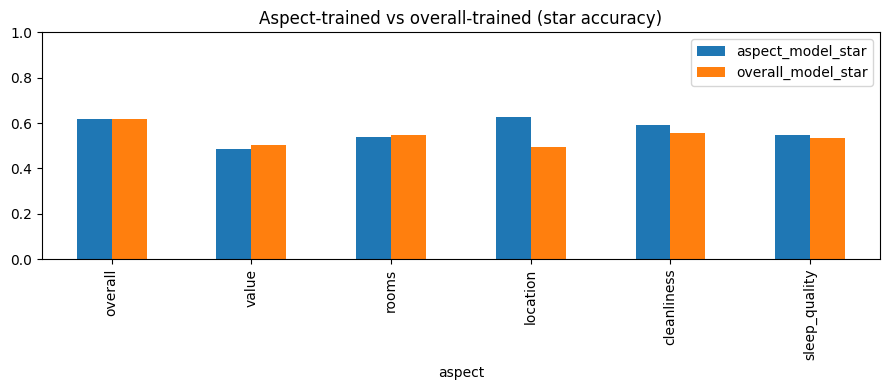

In [12]:
tr = train_df["overall"].notna().values
svm_overall = LinearSVC(C=0.1, class_weight="balanced", random_state=SEED)
svm_overall.fit(X_train_all[tr], train_df.loc[tr, "overall"].astype(int).values)

rows = []
for aspect in ASPECTS:
    te = test_df[aspect].notna().values
    Xte, yte = X_test_all[te], test_df.loc[te, aspect].astype(int).values
    a = evaluate(yte, svm_models[aspect].predict(Xte)); o = evaluate(yte, svm_overall.predict(Xte))
    rows.append({"aspect": aspect, "aspect_model_star": a["star_acc"], "overall_model_star": o["star_acc"],
                 "aspect_model_polarity": a["polarity_acc"], "overall_model_polarity": o["polarity_acc"]})
cmp_df = pd.DataFrame(rows).set_index("aspect")
cmp_df.to_csv("outputs/overall_vs_aspect.csv")
display(cmp_df.round(3))
cmp_df[["aspect_model_star", "overall_model_star"]].plot.bar(figsize=(9, 4))
plt.title("Aspect-trained vs overall-trained (star accuracy)"); plt.ylim(0, 1)
plt.tight_layout(); plt.savefig("outputs/overall_vs_aspect.png", dpi=130); plt.show()

## Step 9: What words drive each aspect? (interpretability)
The Linear SVM learns a weight per phrase. For each aspect we show the phrases that push the prediction toward **5 stars** and toward **1 star**. This is a good slide for your presentation.

In [13]:
vocab = np.array(vec.get_feature_names_out())
for aspect in ASPECTS:
    m = svm_models[aspect]
    w5 = m.coef_[list(m.classes_).index(5)]; w1 = m.coef_[list(m.classes_).index(1)]
    print(f"{aspect:14s} + :", ", ".join(vocab[np.argsort(w5)[-8:][::-1]]))
    print(f"{'':14s} - :", ", ".join(vocab[np.argsort(w1)[-8:][::-1]]), "\n")

overall        + : great hotel, wonderful, amazing, excellent, wonderful hotel, great place, awesome, elegant
               - : terrible, worst, horrible, filthy, dirty, worst hotel, don stay, dump 

value          + : value, great value, great price, staff great, fantastic, bargain, elizabeth, gift
               - : overpriced, filthy, terrible, horrible, awful, worst, dump, never 

rooms          + : elegant, great hotel, was very pleasant, rooms great, classy, beautifully, excellent hotel, sd
               - : worst, filthy, horrible, terrible, awful, dirty, disgusting, smallest 

location       + : great location, excellent location, perfect location, location location, the location, to everything, location is great, awesome
               - : very poor, disgusting, hanging, unsafe, poor, fleas, beware, rather 

cleanliness    + : very clean, classy, spotless, elegant, wonderful hotel, gem, great hotel, rooms are great
               - : dirty, filthy, disgusting, horrible, brok

## Step 10: Save models and run a live demo
`predict_review` is what you show in the demo: type any review and see stars + polarity for every aspect.

In [14]:
joblib.dump({"vectorizer": vec, "models": svm_models}, "outputs/absa_models.joblib")

def predict_review(text):
    X = vec.transform([text])
    out = []
    for aspect, model in svm_models.items():
        s = int(model.predict(X)[0])
        out.append({"aspect": aspect, "stars": s, "polarity": POL_NAME[int(polarity([s])[0])]})
    print("Review:", text)
    return pd.DataFrame(out).set_index("aspect")

predict_review("The room was spotless and the staff were friendly, but the location was far from everything and noisy at night.")

Review: The room was spotless and the staff were friendly, but the location was far from everything and noisy at night.


,stars,polarity
aspect,,
overall,4,positive
value,3,neutral
rooms,5,positive
location,5,positive
cleanliness,5,positive
sleep_quality,5,positive


In [15]:
# Try your own review here
predict_review("Terrible stay. Dirty bathroom, rude front desk, and the bed was very uncomfortable.")

Review: Terrible stay. Dirty bathroom, rude front desk, and the bed was very uncomfortable.


,stars,polarity
aspect,,
overall,1,negative
value,3,neutral
rooms,3,neutral
location,4,positive
cleanliness,1,negative
sleep_quality,1,negative


## Step 11: Automatic findings summary
This cell reads the tables above and prints the key findings for **this run**, so the numbers quoted in your report always match your results.

In [16]:
print("Best model by star accuracy, and gain over the majority baseline:")
for a in ASPECTS:
    r = res[res.aspect == a].set_index("model")["star_acc"]
    b = baseline_df.loc[a, "star_acc"]
    print(f"  {a:14s} best={r.idxmax():10s} ({r.max():.3f}) | baseline={b:.3f} | gain={r.max()-b:+.3f} "
          f"| SVM gain={r['LinearSVM']-b:+.3f}")

print("\nAspect-trained vs overall-trained Linear SVM (star accuracy):")
for a in ASPECTS:
    d = cmp_df.loc[a, "aspect_model_star"] - cmp_df.loc[a, "overall_model_star"]
    verdict = "aspect-specific model BETTER" if d > 0.005 else ("overall model BETTER" if d < -0.005 else "about equal")
    print(f"  {a:14s} {d:+.3f}  -> {verdict}")

Best model by star accuracy, and gain over the majority baseline:
  overall        best=NaiveBayes (0.651) | baseline=0.432 | gain=+0.219 | SVM gain=+0.185
  value          best=NaiveBayes (0.525) | baseline=0.409 | gain=+0.115 | SVM gain=+0.076
  rooms          best=NaiveBayes (0.560) | baseline=0.425 | gain=+0.135 | SVM gain=+0.111
  location       best=NaiveBayes (0.646) | baseline=0.638 | gain=+0.008 | SVM gain=-0.012
  cleanliness    best=NaiveBayes (0.626) | baseline=0.559 | gain=+0.067 | SVM gain=+0.030
  sleep_quality  best=NaiveBayes (0.578) | baseline=0.496 | gain=+0.081 | SVM gain=+0.051

Aspect-trained vs overall-trained Linear SVM (star accuracy):
  overall        +0.000  -> about equal
  value          -0.017  -> overall model BETTER
  rooms          -0.009  -> overall model BETTER
  location       +0.132  -> aspect-specific model BETTER
  cleanliness    +0.033  -> aspect-specific model BETTER
  sleep_quality  +0.014  -> aspect-specific model BETTER


## Step 12: Conclusions
**Setup.** 30,000 TripAdvisor hotel reviews (20,000 train / 10,000 test), predicting the overall rating plus five aspect ratings (value, rooms, location, cleanliness, sleep quality) from review text using 1-3 gram bag-of-words features.

**Model comparison.** Multinomial Naive Bayes achieved the highest star accuracy on every aspect (for example 0.651 for overall, against 0.618 for the Linear SVM and 0.560 for Ridge). The class-balanced Linear SVM gives up some raw accuracy to treat rare classes (1-2 stars) more fairly: on macro-F1 it was ahead of Naive Bayes for rooms (0.463 vs 0.455) and location (0.312 vs 0.285), while Naive Bayes led on the other aspects. Predictions are usually close: within-1-star accuracy is 0.89-0.97 and polarity (negative / neutral / positive) accuracy is 0.76-0.86 across models. Exact-star accuracy is lower (0.45-0.65) because neighbouring ratings such as 4 and 5 stars are hard to tell apart from text.

**Baseline.** Ratings are dominated by 4-5 stars, so a majority-class baseline is strong. The best model (Naive Bayes) beats it on star accuracy by +0.219 for overall, +0.115 for value, +0.135 for rooms, +0.081 for sleep quality and +0.067 for cleanliness, so for these aspects the models genuinely learn from the text. For **location** the gain is only +0.008 (the SVM is 0.012 below the baseline of 0.638), and the location polarity baseline (0.876) is higher than every model (0.861-0.862). We therefore cannot claim the models learned location sentiment beyond predicting the most common rating. Ridge regression on sleep quality only matches the baseline (0.496).

**Aspect-specific vs overall training.** Training on the aspect's own rating helped the Linear SVM for location (+0.132 star accuracy), cleanliness (+0.033) and sleep quality (+0.014), but was slightly worse for value (-0.017) and rooms (-0.009), where overall sentiment already carries most of the signal. The location gain should be read carefully: the overall-trained model scores poorly on location (0.494, below the baseline) because location ratings are skewed to 5 stars, so the aspect-trained model mainly gains by learning that skew rather than by showing strong location skill. Cleanliness is the clearest case of aspect-specific vocabulary helping (e.g. "spotless", "very clean", "dirty").

**Limitations.** (1) Each model reads the whole review, so it cannot tell which sentence is about which aspect; in the demo, a review saying the location was "far from everything" still received a positive location score. (2) Some top features are noise or overall-sentiment words (e.g. "classy" for sleep quality, "elizabeth" for value), showing leakage from overall sentiment and some overfitting; the vocabulary also hit the 300,000-feature cap. (3) Heavy class imbalance toward 5 stars. (4) The dataset has five aspects, not the seven in the original Wang et al. data used in the reference paper, so results are not directly comparable.

**Future work.** Split reviews into sentences and assign each sentence to an aspect before scoring it; use class-rebalancing or ordinal-regression methods; try transformer models such as fine-tuned BERT.
